# Downturn LGD and the regulatory floors

**Question:** Which default years and cohorts does the C08 downturn rule pick, how much LGD does the cohort-based add-on put on top of the long-run level, and do the Basel input floors ever bind on these small-business and revolving-line books?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 03 of this topic
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- identify downturn years from an indicator with `identify_downturn`, and say that the threshold is a policy parameter;
- reproduce the cohort-based downturn add-on of C08 with `downturn_add_on`, from the six cohort means and their numbers of defaults, and check it against the committed rows;
- judge whether a downturn estimate covers the realised downturn loss with `coverage_shortfall`, read the committed `downturn_coverage` tests and say why a green test and an open finding can sit together;
- read the LGD floors of the Basel III final framework with `lgd_floor` and `apply_lgd_floor`, and the EAD floor with `supervisory_ccf`, `ead_floor` and `apply_ead_floor`;
- say where each floor binds, and why in C08 and C09 none does.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you.

In [1]:
# Import the tools and print their versions, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.lgd_ead import downturn, floors

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

Eight committed artifacts. Seven are of case C08, the LGD of small-business loans: the six default-cohort variants `dc-2003-06.json` to `dc-2020-23.json` and the model artifact `models-dc-2007-08.json`, which holds the floors table. The eighth is `data/derived/C09/level-3.json`, the revolving-lines generator of case C09 at acceleration level 3, for the EAD floor. The LGD is the charge-off proxy of notebook 01, so the downturn figures below are a statement about the proxy. The artifacts were baked by older engines than the installed one, and the next cell prints the versions.

The downturn block is a fact of the whole file, not of one cohort: the long-run LGD is taken over the six cohorts, so every variant holds the same table. The cell loads the artifacts, checks that claim by comparing two variants, and prints the period the artifact reports and how it was found.

In [2]:
# Load the artifacts and print the period of the downturn block and the indicator it came from
ROOT = Path("../../..").resolve()
C08, C09 = ROOT / "data" / "derived" / "C08", ROOT / "data" / "derived" / "C09"
COHORTS = ["2003-06", "2007-08", "2009-10", "2011-13", "2014-19", "2020-23"]
cohort = {c: json.loads((C08 / f"dc-{c}.json").read_text(encoding="utf-8")) for c in COHORTS}
models = json.loads((C08 / "models-dc-2007-08.json").read_text(encoding="utf-8"))
level3 = json.loads((C09 / "level-3.json").read_text(encoding="utf-8"))
print("installed riskvalidation:", rv.__version__)
baked = (cohort["2007-08"]["provenance"]["riskvalidation_version"], level3["provenance"]["riskvalidation_version"])
print("baked by (C08, C09):", *baked)
block = cohort["2007-08"]["outputs"]["downturn"]
first_year, last_year = block["period"]["first_year"], block["period"]["last_year"]
print("same block in the 2007-08 and 2009-10 variants:", block == cohort["2009-10"]["outputs"]["downturn"])
print("downturn period found:", first_year, "-", last_year)
print("indicator:", block["period"]["indicator"]["en"])

installed riskvalidation: 1.0.1
baked by (C08, C09): 1.0.1 1.0.1
same block in the 2007-08 and 2009-10 variants: True
downturn period found: 2008 - 2011
indicator: annual charge-off rate of the SBA 7(a) book (charge-offs of the year over loans open on 1 January)


## Method

### Step 1: which years are a downturn?

The engine's `identify_downturn(years, indicator, threshold, higher_is_worse=True)` marks a year as a downturn year when the indicator is strictly above the threshold (a tie is not a downturn; a missing indicator raises an error). The engine does not choose the threshold: it is a **policy parameter**. The C08 pipeline sets it to the mean of the indicator plus one standard deviation of the years read, and uses as indicator the annual charge-off rate of the SBA 7(a) book itself, because no macro path is among its sources (the docstring of the pipeline's `downturn` module). The downturn is the longest run of consecutive flagged years.

The indicator values are not committed, only the period they gave. The next cell shows the rule on an **invented** indicator of eight years, to see the threshold and the flags; the real period is read in step 2.

threshold (mean + 1 standard deviation): 0.0498
downturn years: [2008, 2009]
a value equal to the threshold is flagged: False


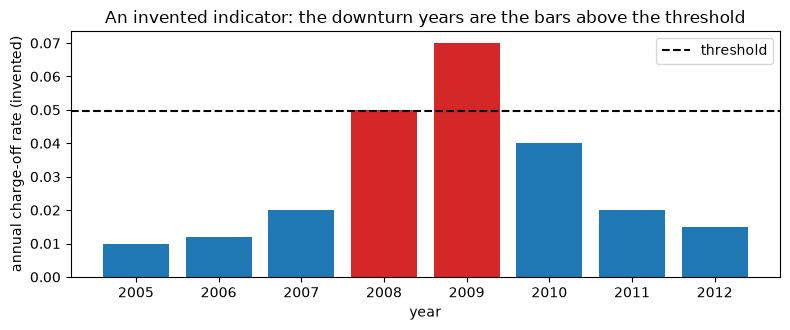

In [3]:
# Apply identify_downturn to an invented indicator of eight years and draw the flagged years
years = np.arange(2005, 2013)
rate = np.array([0.010, 0.012, 0.020, 0.050, 0.070, 0.040, 0.020, 0.015])
threshold = rate.mean() + 1.0 * rate.std()
flags = downturn.identify_downturn(years, rate, threshold)
print(f"threshold (mean + 1 standard deviation): {threshold:.4f}")
print("downturn years:", years[flags].tolist())
tie = downturn.identify_downturn(np.array([2020]), np.array([0.05]), 0.05)
print("a value equal to the threshold is flagged:", bool(tie[0]))

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(years, rate, color=np.where(flags, "tab:red", "tab:blue"))
ax.axhline(threshold, color="black", linestyle="--", label="threshold")
ax.set_xlabel("year")
ax.set_ylabel("annual charge-off rate (invented)")
ax.set_title("An invented indicator: the downturn years are the bars above the threshold")
ax.legend()
fig.tight_layout()
plt.show()

Two of the eight bars, 2008 and 2009, rise above the dashed line and are flagged; 2010 is high but stays below it. The threshold is not a property of the data: moving it to the mean alone would flag 2008 to 2010, and moving it to two standard deviations would flag only 2009. That is why the engine treats it as a policy parameter and why the pipeline of C08 states the rule it used. A year exactly at the threshold is not flagged, a convention the last line of the cell confirms with a value equal to the threshold.

### Step 2: the cohort-based add-on

C08's downturn LGD is Contraste's own cohort-based add-on, an illustration and not a regulatory estimate (the EBA texts on downturn calibration are cross-references in the engine, and the engine states that it claims no regulatory approach). Two numbers are defined by default-weighted means:

$$\text{long-run} = \frac{\sum_k n_k\,\overline{LGD}_k}{\sum_k n_k}, \qquad \text{downturn} = \frac{\sum_{k \in D} n_k\,\overline{LGD}_k}{\sum_{k \in D} n_k}, \qquad \text{add-on} = \text{downturn} - \text{long-run}$$

where $k$ runs over the six cohorts, $\overline{LGD}_k$ is the mean proxy of cohort $k$, $n_k$ its number of defaults and $D$ the set of downturn cohorts. (Source: the docstring of `downturn_add_on`.) The pipeline's rule for $D$ is that a cohort is a downturn cohort when at least half of its default years are downturn years.

The next cell reads each cohort's years, mean and number of defaults from its own variant, applies the rule to the period of step 1's artifact (2008 to 2011), calls `downturn_add_on` and compares the result with the committed add-on. Every intermediate is printed.

In [4]:
# Mark the downturn cohorts by the half-of-the-years rule and call downturn_add_on
first, last = block["period"]["first_year"], block["period"]["last_year"]
cohort_lgd, weights, mask = [], [], []
print(f"{'cohort':8s} {'years':>6s} {'in the period':>14s} {'n':>8s} {'mean':>9s} {'downturn':>16s}")
for c in COHORTS:
    meta = cohort[c]["outputs"]["cohort"]
    span = range(meta["first_year"], meta["last_year"] + 1)
    inside = sum(first <= y <= last for y in span)
    d = cohort[c]["outputs"]["lgd_distribution"]
    cohort_lgd.append(d["mean"]["value"])
    weights.append(d["n"])
    mask.append(inside / len(span) >= 0.5)
    print(f"{c:8s} {len(span):6d} {inside:14d} {d['n']:8,d} {d['mean']['value']:9.4f} {mask[-1]!s:>16}")

share = np.dot(weights, mask) / sum(weights)
print(f"share of the defaults in downturn cohorts: {share:.3f}")
result = downturn.downturn_add_on(np.array(cohort_lgd), np.array(weights, float), np.array(mask))
committed = block["rows"][0]
print(f"long-run LGD: {result.long_run:.6f} | downturn LGD: {result.downturn:.6f}")
print(f"add-on: {result.add_on:.6f}")
long_run, down = committed["long_run_lgd"]["value"], committed["downturn_lgd"]["value"]
print(f"committed: {long_run:.6f} | {down:.6f} | {committed['add_on']:.6f}")
picked = [c for c, m in zip(COHORTS, mask) if m]
print("the rule picks the committed cohorts:", picked == [r["cohort_id"] for r in block["rows"]])

cohort    years  in the period        n      mean         downturn
2003-06       4              0   21,919    0.7081            False
2007-08       2              1   25,299    0.8178             True
2009-10       2              2   50,281    0.8221             True
2011-13       3              1   33,673    0.7416            False
2014-19       6              0   36,481    0.6631            False
2020-23       4              0   13,930    0.7311            False
share of the defaults in downturn cohorts: 0.416
long-run LGD: 0.753873 | downturn LGD: 0.820644
add-on: 0.066770
committed: 0.753873 | 0.820644 | 0.066770
the rule picks the committed cohorts: True


The two cohorts that the rule flags are 2007-08 and 2009-10, the two with the highest mean indicator, and the weighted means give the long-run level, the downturn level and their difference. The committed row agrees to six decimals, so the cohort rule and the engine's `downturn_add_on` are what produced the artifact. The size of the add-on is modest because the long-run mean already contains the two high cohorts: the downturn cohorts hold 41.6% of the defaults used. A different threshold would flag different cohorts and a different add-on, which is the policy dependence of step 1 carried through.

### Step 3: does the estimate cover the downturn loss?

An estimate that is supposed to hold in a downturn should be at least the loss realised in one. `coverage_shortfall(estimate, realised)` returns whether the estimate covers the realised value and by how much it falls short, with a tolerance of $10^{-12}$: $\text{covered} = \text{estimate} \ge \text{realised} - 10^{-12}$ and $\text{shortfall} = \max(0, \text{realised} - \text{estimate})$. The engine's test `downturn_coverage` adds the loan-level view: it tests whether the mean realised downturn LGD exceeds the estimate with a one-sided t statistic on the loans of the cohort, $t = (\overline{y} - \text{estimate}) / (s / \sqrt{n})$, and colours it with a Contraste internal gate (green when the p-value is at least 0.05, amber from 0.01, red below). The loans themselves are not committed, so the test rows are read from the artifact, with the engine version that baked them.

The cell applies `coverage_shortfall` to the two downturn cohorts and prints the committed test rows and the finding the pipeline recorded.

In [5]:
# Apply coverage_shortfall to the two downturn cohorts and print the committed test rows and the finding
light = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}
for row in block["rows"]:
    estimate, realised = row["downturn_lgd"]["value"], row["crisis_realised_lgd"]["value"]
    covered, shortfall = downturn.coverage_shortfall(estimate, realised)
    print(f"cohort {row['cohort_id']}: estimate {estimate:.6f} realised {realised:.6f}"
          f" | covered {covered}, shortfall {shortfall:.6f}")
print()
print("tests baked by riskvalidation:", cohort["2007-08"]["provenance"]["riskvalidation_version"])
for t in cohort["2007-08"]["tests"]:
    if t["test_id"] == "lgd_ead.downturn_coverage":
        stat = f"t={t['statistic']:7.4f} p={t['p_value']:.4f}"
        print(f"{t['segment']:17s} {stat} shortfall={t['metric']:.6f} light: {light[t['light']]}")
for f in cohort["2007-08"]["findings"]:
    if f["id"] == "F-downturn-coverage":
        print("finding", f["id"], f["severity"], f["status"])

cohort 2007-08: estimate 0.820644 realised 0.817782 | covered True, shortfall 0.000000
cohort 2009-10: estimate 0.820644 realised 0.822083 | covered False, shortfall 0.001440

tests baked by riskvalidation: 1.0.1
cohort-2007-08    t=-1.4010 p=0.9194 shortfall=0.000000 light: green
cohort-2009-10    t= 0.9655 p=0.1671 shortfall=0.001440 light: green
finding F-downturn-coverage S3 open


The point estimate falls short of the realised loss of 2009-10 by a small amount, so the pipeline records an open finding of severity S3; the test cannot reject that the mean realised LGD is at or below the estimate, so its light is green. Both are true: a shortfall exists in the mean, and it is too small, against the dispersion of 50,281 proxies, to be statistically distinguishable from zero. A validator reads the two together and does not collapse them into one verdict.

### Step 4: the LGD floors

The Basel III final framework sets input floors for the LGD an advanced-approach bank may use, by portfolio and collateral (CRE32.16 for corporate, CRE32.58 and CRE32.59 for retail; the engine's `floors` module transcribes the cells from the research and marks the order of some retail cells UNVERIFIED against the paragraph text). `lgd_floor(portfolio, collateral)` returns the cell and raises for a combination with no cell. `apply_lgd_floor(lgd, floor)` returns the floored estimates, which loans the floor raises, the mean before and after and the uplift, $\max(\text{LGD}, \text{floor})$ loan by loan.

The first cell asks the engine for the floor of every portfolio and collateral cell of the C08 artifact's table and prints them with their paragraph references. The second applies the 25% corporate unsecured floor to eight **invented** LGDs, a mix of low and high values, and draws what a binding floor does.

In [6]:
# Ask the engine for the floor of each cell of the artifact's table and print it with its paragraph
cells = models["fit"]["floors"]["cells"]
portfolio = {"corporate": "corporate", "retail": "retail"}
collateral = {"unsecured": "unsecured", "financial": "financial", "receivables": "receivables",
              "real-estate": "real estate", "other-physical": "other physical", "mortgage": "mortgage",
              "qrre": "qualifying revolving (QRRE)"}
for cell in cells:
    kind, security = cell["portfolio"], cell["collateral"]
    floor = floors.lgd_floor(kind, security)
    print(f"{portfolio[kind]:12s} {collateral[security]:28s} floor {floor:.2f}  ({cell['reference']})")

corporate    unsecured                    floor 0.25  (CRE32.16)
corporate    financial                    floor 0.00  (CRE32.16)
corporate    receivables                  floor 0.10  (CRE32.16)
corporate    real estate                  floor 0.10  (CRE32.16)
corporate    other physical               floor 0.15  (CRE32.16)
retail       mortgage                     floor 0.05  (CRE32.58 to CRE32.59)
retail       qualifying revolving (QRRE)  floor 0.50  (CRE32.58 to CRE32.59)
retail       unsecured                    floor 0.30  (CRE32.58 to CRE32.59)
retail       financial                    floor 0.00  (CRE32.58 to CRE32.59)
retail       receivables                  floor 0.10  (CRE32.58 to CRE32.59)
retail       real estate                  floor 0.10  (CRE32.58 to CRE32.59)
retail       other physical               floor 0.15  (CRE32.58 to CRE32.59)


The second cell, below, is the effect of a floor on a small set of numbers.

floor binds on 4 of 8 | share 0.500
mean before 0.3412 | mean after 0.4062 | uplift 0.0650


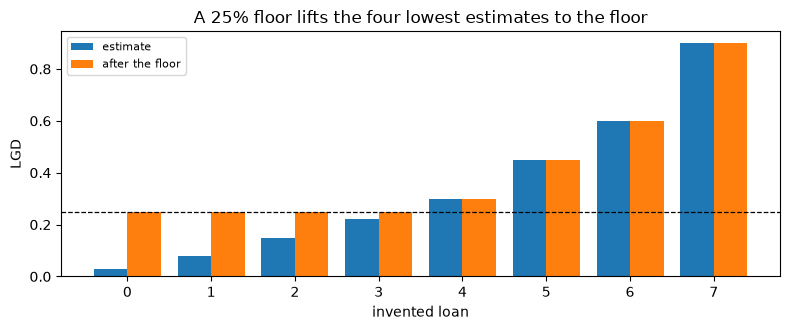

In [7]:
# Apply a 25% floor to eight invented LGDs and draw them before and after
invented = np.array([0.03, 0.08, 0.15, 0.22, 0.30, 0.45, 0.60, 0.90])
bite = floors.apply_lgd_floor(invented, floors.lgd_floor("corporate", "unsecured"))
print(f"floor binds on {int(bite.binding.sum())} of {invented.size} | share {bite.share_binding:.3f}")
print(f"mean before {bite.mean_before:.4f} | mean after {bite.mean_after:.4f} | uplift {bite.uplift:.4f}")

fig, ax = plt.subplots(figsize=(8, 3.4))
positions = np.arange(invented.size)
ax.bar(positions - 0.2, invented, width=0.4, color="tab:blue", label="estimate")
ax.bar(positions + 0.2, bite.applied, width=0.4, color="tab:orange", label="after the floor")
ax.axhline(0.25, color="black", linestyle="--", linewidth=0.9)
ax.set_xticks(positions)
ax.set_xlabel("invented loan")
ax.set_ylabel("LGD")
ax.set_title("A 25% floor lifts the four lowest estimates to the floor")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The four estimates below 0.25 are lifted to the dashed line and the four above it are untouched, so the mean moves from 0.3412 to 0.4062. A floor is therefore a clamp from below, and its effect depends entirely on how much of the book sits underneath it: here half of it does, because the eight values were invented to straddle the floor. The real books below do not, which is the finding of the next step.

### Step 5: where the LGD floor binds in C08

The C08 artifact applies the floors to the fractional-logit predictions of each cohort, by segment (`outputs.floors_bite`). The SBA file has no collateral field, so the pipeline infers the collateral from the term and the revolving status (lines of credit and loans up to 7 years as unsecured, 7 to 20 years as other physical, 20 years or more as real estate), as the artifact's own note says; the floor of each segment follows. The bite is the mean uplift. The cell prints the 2007-08 and 2009-10 tables and draws the mean predicted LGD of each segment against its floor.

sme-revolver         corporate-unsecured        floor 0.25  n= 7,864 mean before 0.8903  share binding 0.000 uplift 0.0000
sme-term-up-to-84    corporate-unsecured        floor 0.25  n=14,454 mean before 0.7254  share binding 0.000 uplift 0.0000
sme-term-85-239      corporate-other-physical   floor 0.15  n= 2,739 mean before 0.6270  share binding 0.000 uplift 0.0000
sme-term-240-plus    corporate-real-estate      floor 0.10  n=   242 mean before 0.6017  share binding 0.000 uplift 0.0000
2009-10: largest share binding 0.0


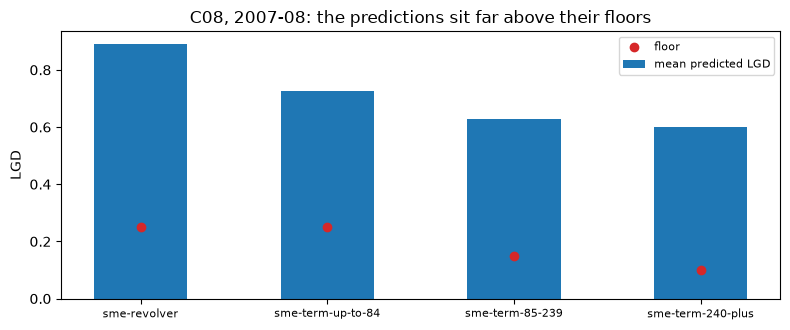

In [8]:
# Print the committed floors_bite table and draw each segment's mean prediction against its floor
rows = cohort["2007-08"]["outputs"]["floors_bite"]["rows"]
for r in rows:
    head = f"{r['segment_id']:20s} {r['floor_id']:26s} floor {r['floor']:.2f}  n={r['n']:6,d}"
    tail = f"mean before {r['mean_before']['value']:.4f}  share binding {r['share_binding']:.3f}"
    print(head, tail, f"uplift {r['uplift']:.4f}")
rows_2 = cohort["2009-10"]["outputs"]["floors_bite"]["rows"]
print("2009-10: largest share binding", max(r["share_binding"] for r in rows_2))

fig, ax = plt.subplots(figsize=(8, 3.4))
positions = np.arange(len(rows))
ax.bar(positions, [r["mean_before"]["value"] for r in rows], width=0.5, color="tab:blue", label="mean predicted LGD")
ax.scatter(positions, [r["floor"] for r in rows], color="tab:red", zorder=3, label="floor")
ax.set_xticks(positions)
ax.set_xticklabels([r["segment_id"] for r in rows], fontsize=8)
ax.set_ylabel("LGD")
ax.set_title("C08, 2007-08: the predictions sit far above their floors")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Every bar stands well above its red marker: the mean predicted LGD of the C08 segments runs from 0.6017 to 0.8903 while the floors are 0.10 to 0.25, so the share of loans where the floor binds is zero in 2007-08, and the cell prints the same zero as the largest share of 2009-10. The charge-off indicator has high values by construction, because it is the written-off share of an approved amount. A floor designed for a mortgage book with LGDs of 10 to 20% would matter there; on this book it never does, and the figure shows why the floor tables of this step are a check that is cheap to run and rarely binding.

### Step 6: the EAD floor

The EAD floor of the same framework (CRE32.36 for corporate, CRE32.64 for retail) reads "on-balance amount plus 50% of the off-balance exposure using the standardised CCF". The engine's formula is $\text{floor} = E + s\,c\,\max(L - E, 0)$ with $s$ the off-balance share (0.5) and $c$ the supervisory conversion factor of the facility class, which `supervisory_ccf(item)` returns (for instance 0.4 for commitments, CRE20.98, and 0.1 for unconditionally cancellable lines, CRE20.100). The reading that the 50% applies to the CCF-weighted off-balance exposure follows the research wording and the engine marks it UNVERIFIED against the paragraph text. An overdrawn line has no off-balance amount, so its floor is its drawn amount. `apply_ead_floor(ead, floor)` takes the elementwise maximum.

The cell lists the five supervisory factors, applies the floor to three **invented** facilities (one of them overdrawn), and then reads what the C09 artifact reports for the same rule on its generator lines.

In [9]:
# List the supervisory CCFs, apply the EAD floor to three invented facilities and read the floor block of C09
item = {"direct-credit-substitutes": "direct credit substitutes",
        "nifs-rufs-transaction-related-contingents": "NIFs, RUFs, transaction-related contingents",
        "commitments": "commitments",
        "short-term-self-liquidating-trade-letters-of-credit": "short-term trade letters of credit",
        "unconditionally-cancellable": "unconditionally cancellable"}
for name in floors.SUPERVISORY_CCF:
    print(f"{item[name]:56s} {floors.supervisory_ccf(name):.1f}")
drawn = np.array([20.0, 60.0, 110.0])
limit = np.array([100.0, 100.0, 100.0])
sa_ccf = np.full(3, floors.supervisory_ccf("commitments"))
floor_ead = floors.ead_floor(drawn, limit, sa_ccf)
estimate = np.array([40.0, 70.0, 105.0])
bite_ead = floors.apply_ead_floor(estimate, floor_ead)
print("drawn:", drawn, "| limit:", limit)
print("EAD floor:", floor_ead, "| invented estimates:", estimate, "| after the floor:", bite_ead.applied)
print(f"the floor binds on {int(bite_ead.binding.sum())} of {estimate.size}")
eadf = level3["outputs"]["ead_floor"]
for r in eadf["rows"]:
    label = item[r["facility_class"]]
    head = f"C09 {label:44s} CCF {r['sa_ccf']:.1f} ({r['reference']}) n={r['n']:,}"
    print(head, f"share binding {r['share_binding']:.3f}")

direct credit substitutes                                1.0
NIFs, RUFs, transaction-related contingents              0.5
commitments                                              0.4
short-term trade letters of credit                       0.2
unconditionally cancellable                              0.1
drawn: [ 20.  60. 110.] | limit: [100. 100. 100.]
EAD floor: [ 36.  68. 110.] | invented estimates: [ 40.  70. 105.] | after the floor: [ 40.  70. 110.]
the floor binds on 1 of 3
C09 unconditionally cancellable                  CCF 0.1 (CRE20.100) n=38,817 share binding 0.000
C09 commitments                                  CCF 0.4 (CRE20.98) n=38,817 share binding 0.000


## Results

**Answer:** The rule flags 2008 to 2011 and picks the cohorts 2007-08 and 2009-10, which hold 41.6% of the defaults; the cohort-based add-on is 0.066770 on top of a long-run LGD of 0.753873, a downturn LGD of 0.820644 that covers the realised 0.817782 of 2007-08 and falls short of 2009-10 by 0.001440. The Basel floors do not bind on these books: the mean predicted LGD of the C08 segments runs from 0.6017 to 0.8903 against floors of 0.10 to 0.25, and the EAD floor binds on none of the 38,817 defaulted C09 lines, whereas on eight invented LGDs a 25% floor binds on 4 and lifts the mean from 0.3412 to 0.4062.

- **The threshold is a policy choice.** On the invented indicator the threshold (mean plus one standard deviation) is 0.0498, and only 2008 and 2009 lie above it; a value exactly at the threshold is not flagged.
- **The add-on is reproduced.** With the real period of 2008 to 2011, the half-of-the-years rule picks the cohorts 2007-08 (one of its two years inside the period) and 2009-10 (both). `downturn_add_on` gives a long-run LGD of 0.753873, a downturn LGD of 0.820644 and an add-on of 0.066770, equal to the committed row to six decimals. The add-on is a difference of two means of an indicator, not a regulatory estimate.
- **A green test and an open finding coexist.** The estimate covers the realised loss of 2007-08 and falls short of 2009-10 by 0.001440. The `downturn_coverage` tests are green in both (p-values 0.9194 and 0.1671), and the pipeline keeps the finding open at severity S3: the shortfall exists in the mean and is small against the dispersion of 50,281 loans.
- **The floors are a table the engine answers.** `lgd_floor` returns a floor for each of the 12 cells of the artifact's table, from 0.00 for financial collateral to 0.50 for qualifying revolving retail exposures. On eight invented LGDs the 25% floor binds on four and lifts the mean by 0.0650.
- **In C08 and C09 no floor binds.** Every C08 segment shows a share binding of 0.000 in 2007-08 and in 2009-10, and the C09 EAD floor binds on none of the 38,817 defaulted lines under either supervisory factor. The invented EAD example does bind on one line of three, the overdrawn one, whose floor is its drawn amount of 110.

What the notebook does not do: it does not estimate a downturn LGD for a regulator or validate a floor. The indicator has high values by construction, so a floor that matters in a low-LGD mortgage book does not matter here; the invented examples exist to show the arithmetic where it does. The next notebook measures the bias of the CCF estimators against the known truth of C09.

## Summary

- `identify_downturn` marks the years whose indicator is strictly above a threshold that is a policy parameter; the C08 pipeline takes the mean plus one standard deviation of the book's own annual charge-off rate and the longest run of flagged years.
- The cohort-based add-on is a difference of default-weighted means, `downturn_add_on`; it reproduces the committed rows once the half-of-the-years rule picks the cohorts. It is an illustration, not a regulatory estimate.
- Coverage is judged on the point estimate (`coverage_shortfall`) and on the loans (`downturn_coverage`); the two can differ, and both are reported.
- The LGD floors are a table by portfolio and collateral (`lgd_floor`, `apply_lgd_floor`) and the EAD floor is the drawn amount plus half of the CCF-weighted undrawn amount (`ead_floor`, `apply_ead_floor`). In C08 and C09 no floor binds.

**What to try next.** Lower the invented EAD estimates of step 6 and see the floor start to bind; apply the 5% retail mortgage floor to a set of low LGDs. Then continue with notebook 05, which measures how the choice of reference date biases the CCF.

## References

- BCBS, Basel Framework, CRE32 (internal ratings-based approach; the LGD input floors, CRE32.16 and CRE32.58 to CRE32.59, and the EAD floor, CRE32.36 and CRE32.64, as transcribed in the engine's `floors` module). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- BCBS (2017), Basel III: Finalising post-crisis reforms (d424). https://www.bis.org/bcbs/publ/d424.htm
- EBA/RTS/2018/04 and EBA/GL/2019/03 on downturn estimation: cross-references only in the engine's `downturn` module, which states that the add-on is Contraste's cohort-based one and claims no regulatory approach.
- The engine's own documentation: `riskvalidation.lgd_ead.downturn` and `riskvalidation.lgd_ead.floors` (release 0.8.1).
- This repository: `docs/design/SDD.md` (cases C08 and C09), `data-pipeline/pipeline/cases/c08/downturn.py` (the rule for the downturn cohorts) and `data/derived/C08/`, `data/derived/C09/level-3.json`.